# Оценка эффективности промоакций методом Diff-in-Diff

**Задача.** Сеть из 20 магазинов провела четыре акции. Нужно понять, какие из них принесли дополнительную прибыль, какие проели маржу, и научиться точнее планировать продажи следующих волн.

**Почему нельзя просто сравнить «до» и «после».** Летом напитки растут сами по себе. Рост продаж в недели акции складывается из сезона, погоды и самой акции. Чтобы выделить вклад акции, сравниваем магазины с акцией с контрольными магазинами за те же недели.

Данные синтетические: структура повторяет построчную выгрузку чеков из 1С.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import analysis, config, generate_data, mart
from src.did import build_panel, naive_before_after, did_estimate

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))

if not (config.DATA_RAW / "checks.parquet").exists():
    generate_data.main()
if not (config.DATA_MART / "mart_store_week.csv").exists():
    mart.build_marts()
marts = mart.load_marts()

## 1. Данные

Каждая строка: позиция чека. Поля как в выгрузке 1С: номер чека, дата и время, магазин, товар, категория, количество, цена полки, скидка, себестоимость строки и код акции, по которой дана скидка.

In [2]:
con = mart.connect()
print(con.execute("""
    SELECT count(*) AS lines, count(DISTINCT receipt_id) AS receipts,
           count(DISTINCT store_id) AS stores, count(DISTINCT sku_id) AS skus,
           min(datetime)::DATE AS first_day, max(datetime)::DATE AS last_day
    FROM checks""").df().to_string(index=False))
con.execute("SELECT * FROM checks WHERE promo_id = 'P1-1' LIMIT 5").df()

  lines  receipts  stores  skus  first_day   last_day
1411329    457307      20   301 2026-01-05 2026-07-19


,receipt_id,datetime,store_id,sku_id,category,qty,price,discount,cost,promo_id
0,402546,2026-03-23 08:00:00,S18,SKU0059,Газированные напитки,3,69.00,69.00,131.97,P1-1
1,33429,2026-03-23 08:03:00,S02,SKU0028,Газированные напитки,3,59.00,59.00,106.56,P1-1
2,33429,2026-03-23 08:03:00,S02,SKU0044,Газированные напитки,3,89.00,89.00,148.35,P1-1
3,90146,2026-03-23 08:03:00,S05,SKU0033,Газированные напитки,3,89.00,89.00,150.99,P1-1
4,53896,2026-03-23 08:05:00,S03,SKU0002,Газированные напитки,3,99.00,99.00,182.46,P1-1


In [3]:
marts["promo_calendar"][["promo_id", "name", "category", "wave", "start_date", "end_date"]]

,promo_id,name,category,wave,start_date,end_date
0,P3-1,Подарок к чеку от 800 руб,Весь чек,1,2026-02-02,2026-02-22
1,P1-1,1+1=3 на газированные напитки,Газированные напитки,1,2026-03-23,2026-04-12
2,P1-2,1+1=3 на газированные напитки,Газированные напитки,2,2026-06-15,2026-07-05
3,P2-1,-20% на соки и нектары,Соки и нектары,1,2026-04-13,2026-05-03
4,P2-2,-20% на соки и нектары,Соки и нектары,2,2026-06-15,2026-07-05
5,P4-1,Второй энергетик за полцены,Энергетики,1,2026-05-04,2026-05-24
6,P4-2,Второй энергетик за полцены,Энергетики,2,2026-06-15,2026-07-05


## 2. Витрины на SQL

Витрины собираются в DuckDB скриптами из папки `sql/`:
- `mart_store_week`: магазин x неделя (чеки, выручка, маржа, средний чек);
- `mart_group_week`: магазин x неделя x товарная группа акции (участники, неучастники той же категории, прочие категории);
- `mart_promo_spend`: сколько денег роздано скидками и подарками.

Группа товара определяется по списку SKU акции, а не по флагу скидки: так в анализ попадают и недели до акции, и магазины без акции. Перед анализом выполняются проверки качества.

In [4]:
print((config.SQL_DIR / "02_mart_group_week.sql").read_text(encoding="utf-8"))

-- Витрина магазин x неделя x товарная группа акции.
-- Группы для каждой кампании с товарной механикой:
--   "<кампания> участники"       : SKU из списка акции;
--   "<кампания> не участники"    : остальные SKU той же категории (каннибализация);
--   "Прочие категории"           : категории, не задействованные ни в одной акции (эффект на корзину);
--   "Подарок"                    : подарочные строки акции P3.
-- Группа строится по списку SKU кампании, а не по флагу promo_id:
-- так в окно попадают и недели до акции, и магазины без акции.
CREATE OR REPLACE TABLE mart_group_week AS
WITH promo_cat AS (
    SELECT DISTINCT campaign, category
    FROM promo_calendar
    WHERE mechanic <> 'gift'
),
labeled AS (
    SELECT
        c.store_id,
        date_diff('week', DATE '2026-01-05', CAST(date_trunc('week', c.datetime) AS DATE)) AS week,
        CASE
            WHEN c.category = 'Подарок'   THEN 'Подарок'
            WHEN ps.campaign IS NOT NULL  THEN ps.campaign || ' участники'
       

In [5]:
quality = mart.build_marts()["quality_checks"]
quality

,check_name,failed
0,Выручка витрины магазинов совпадает с чеками,False
1,Выручка витрины групп совпадает с чеками,False
2,Нет строк с нулевым или отрицательным количеством,False
3,Скидка не превышает сумму строки,False
4,В каждой паре магазин x неделя есть чеки,False
5,Скидки акций есть только в магазинах и неделях...,False


In [6]:
marts = mart.load_marts()
marts["mart_group_week"].query("store_id == 'S01' and week == 12")

,store_id,week,promo_group,units,revenue,margin,discount,lines
72,S01,12,P1 не участники,465.00,52 955.00,21 185.11,0.00,370
73,S01,12,P1 участники,173.00,17 457.00,7 302.00,0.00,144
74,S01,12,P2 участники,472.00,63 258.00,32 008.35,0.00,372
75,S01,12,P4 не участники,127.00,13 123.00,5 345.34,0.00,95
76,S01,12,P4 участники,134.00,15 796.00,5 915.39,0.00,106
77,S01,12,Прочие категории,2 055.00,215 065.00,79 576.19,0.00,1635


## 3. Почему оценка «до/после» завышает эффект

Сравним рост продаж участников в магазинах акции с ростом в контрольных магазинах за те же недели. Контрольные магазины тоже растут: это сезон, который наивная оценка приписывает акции.

In [7]:
rows = []
for pid in analysis.WAVE1:
    outcome = "store_revenue" if pid.startswith("P3") else "part_units"
    p = build_panel(marts, pid)
    ctrl = p[p.treat == 0]
    ctrl_growth = ctrl.loc[ctrl.period == "акция", outcome].mean() / ctrl.loc[ctrl.period == "до акции", outcome].mean() - 1
    rows.append({
        "акция": pid,
        "показатель": outcome,
        "рост в магазинах акции (до/после)": naive_before_after(p, outcome),
        "рост в контрольных магазинах": ctrl_growth,
        "эффект DiD": did_estimate(p, outcome, log=True)["effect_pct"],
    })
cmp = pd.DataFrame(rows)
cmp.style.format({c: "{:.1%}" for c in cmp.columns[2:]})

,акция,показатель,рост в магазинах акции (до/после),рост в контрольных магазинах,эффект DiD
0,P3-1,store_revenue,13.4%,2.0%,11.8%
1,P1-1,part_units,347.0%,6.9%,316.8%
2,P2-1,part_units,76.4%,2.2%,72.3%
3,P4-1,part_units,152.7%,6.2%,136.7%


## 4. Модель Diff-in-Diff

Для каждого показателя магазина за неделю:

$$y_{st} = \beta \cdot (treat_s \times promo_t) + \alpha_s + \gamma_t + \varepsilon_{st}$$

- $\alpha_s$: фиксированный эффект магазина (разный масштаб точек);
- $\gamma_t$: фиксированный эффект недели (сезон, погода, праздники: общие для всех магазинов);
- $\beta$: эффект акции в рублях или штуках на магазин в неделю;
- стандартные ошибки кластеризованы по магазинам.

Окно: 4 недели до старта и 3 недели акции. Для товарных акций отдельно оцениваются участники, неучастники той же категории (каннибализация) и прочие категории (эффект на корзину).

In [8]:
effects = analysis.effects_table(marts)
view = effects[["promo_id", "label", "coef", "effect_pct", "ci_low", "ci_high", "p_value"]].copy()
view.style.format({"coef": "{:,.0f}", "effect_pct": "{:+.1%}", "ci_low": "{:,.0f}",
                   "ci_high": "{:,.0f}", "p_value": "{:.3f}"})

,promo_id,label,coef,effect_pct,ci_low,ci_high,p_value
0,P3-1,"Выручка магазина, руб","32,457",+11.1%,"17,560","47,353",0.000
1,P3-1,"Маржа магазина с учётом подарков, руб","7,660",+6.6%,"2,201","13,120",0.006
2,P3-1,Число чеков,39,+5.1%,7,71,0.018
3,P3-1,"Средний чек, руб",23,+6.0%,17,30,0.000
4,P1-1,"Продажи участников, шт",541,+319.0%,460,623,0.000
5,P1-1,"Выручка участников, руб","33,566",+198.3%,"28,337","38,795",0.000
6,P1-1,"Маржа участников, руб","2,704",+38.3%,"2,161","3,247",0.000
7,P1-1,"Выручка неучастников категории, руб","-16,218",-33.6%,"-19,679","-12,757",0.000
8,P1-1,"Маржа категории, руб","-3,771",-14.3%,"-4,962","-2,580",0.000
9,P1-1,"Маржа прочих категорий, руб",253,+0.4%,"-3,132","3,639",0.883


## 5. Проверка допущения о параллельных трендах

DiD работает, если без акции магазины двух групп менялись бы одинаково. Проверяем это на неделях до старта: оцениваем эффект для каждой недели (event study) и совместно тестируем, что все эффекты до старта равны нулю.

In [9]:
es = analysis.event_studies(marts)
pretrends = analysis.pretrend_test(es)
pretrends

,promo_id,max_abs_pre_effect,joint_p_value,parallel_trends_ok
0,P1-1,0.06,0.34,True
1,P2-1,0.02,1.00,True
2,P3-1,0.03,0.69,True
3,P4-1,0.17,0.08,True


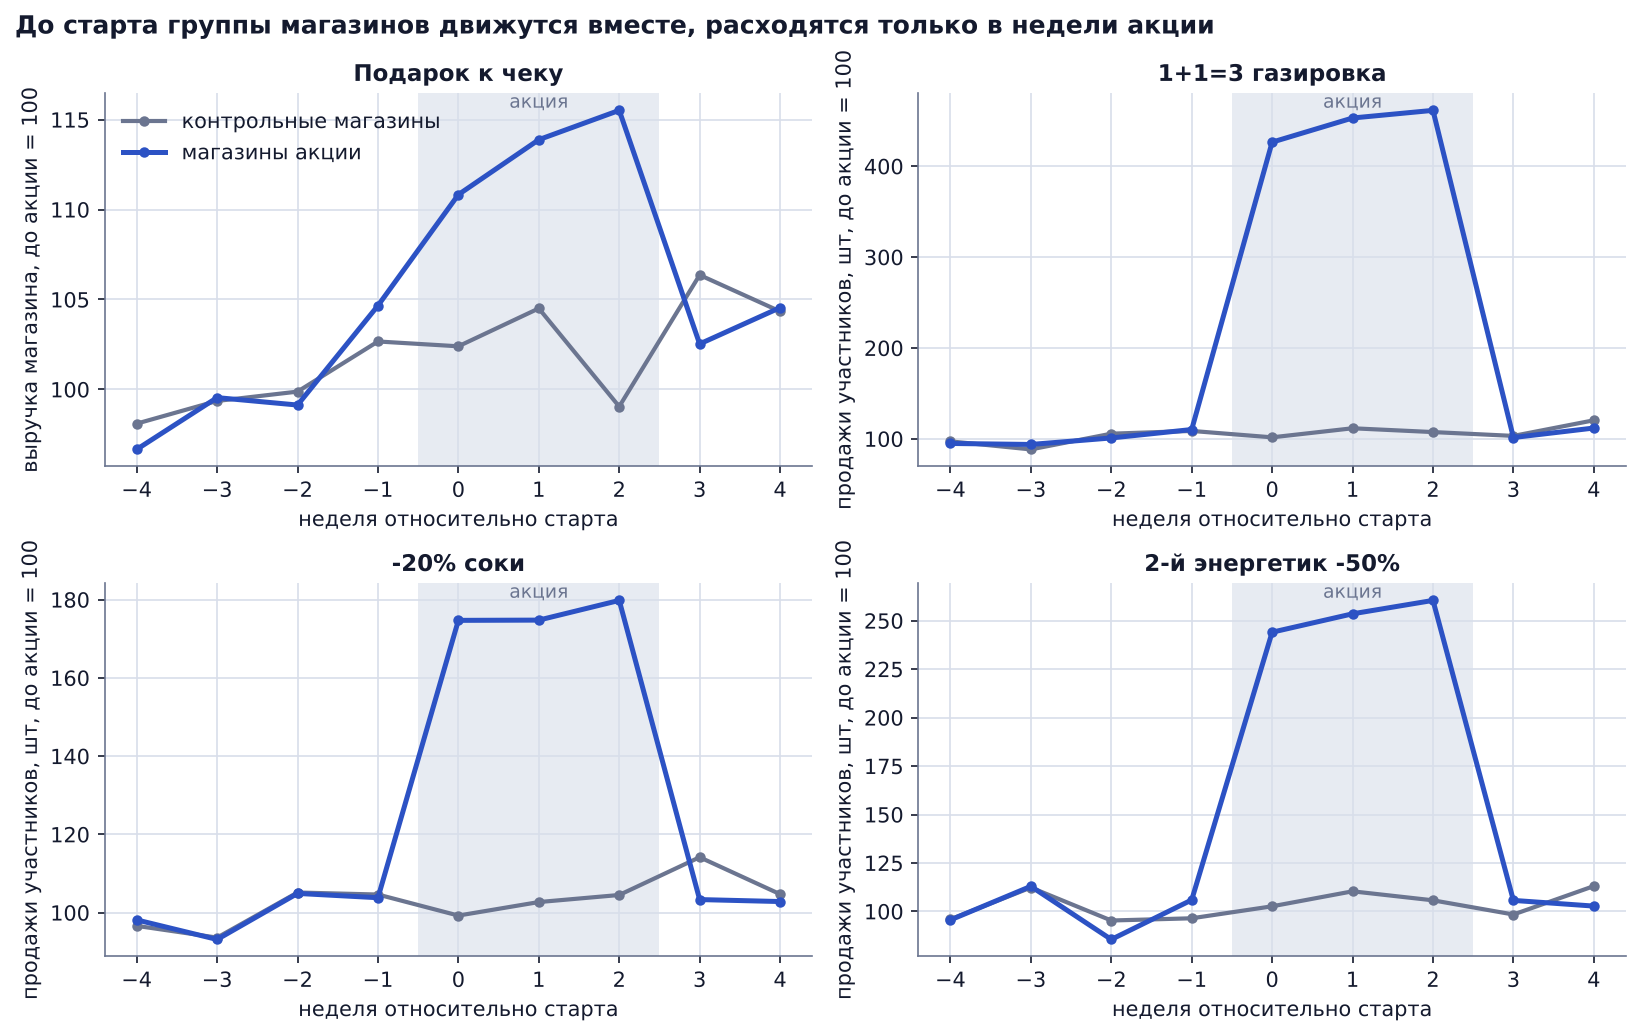

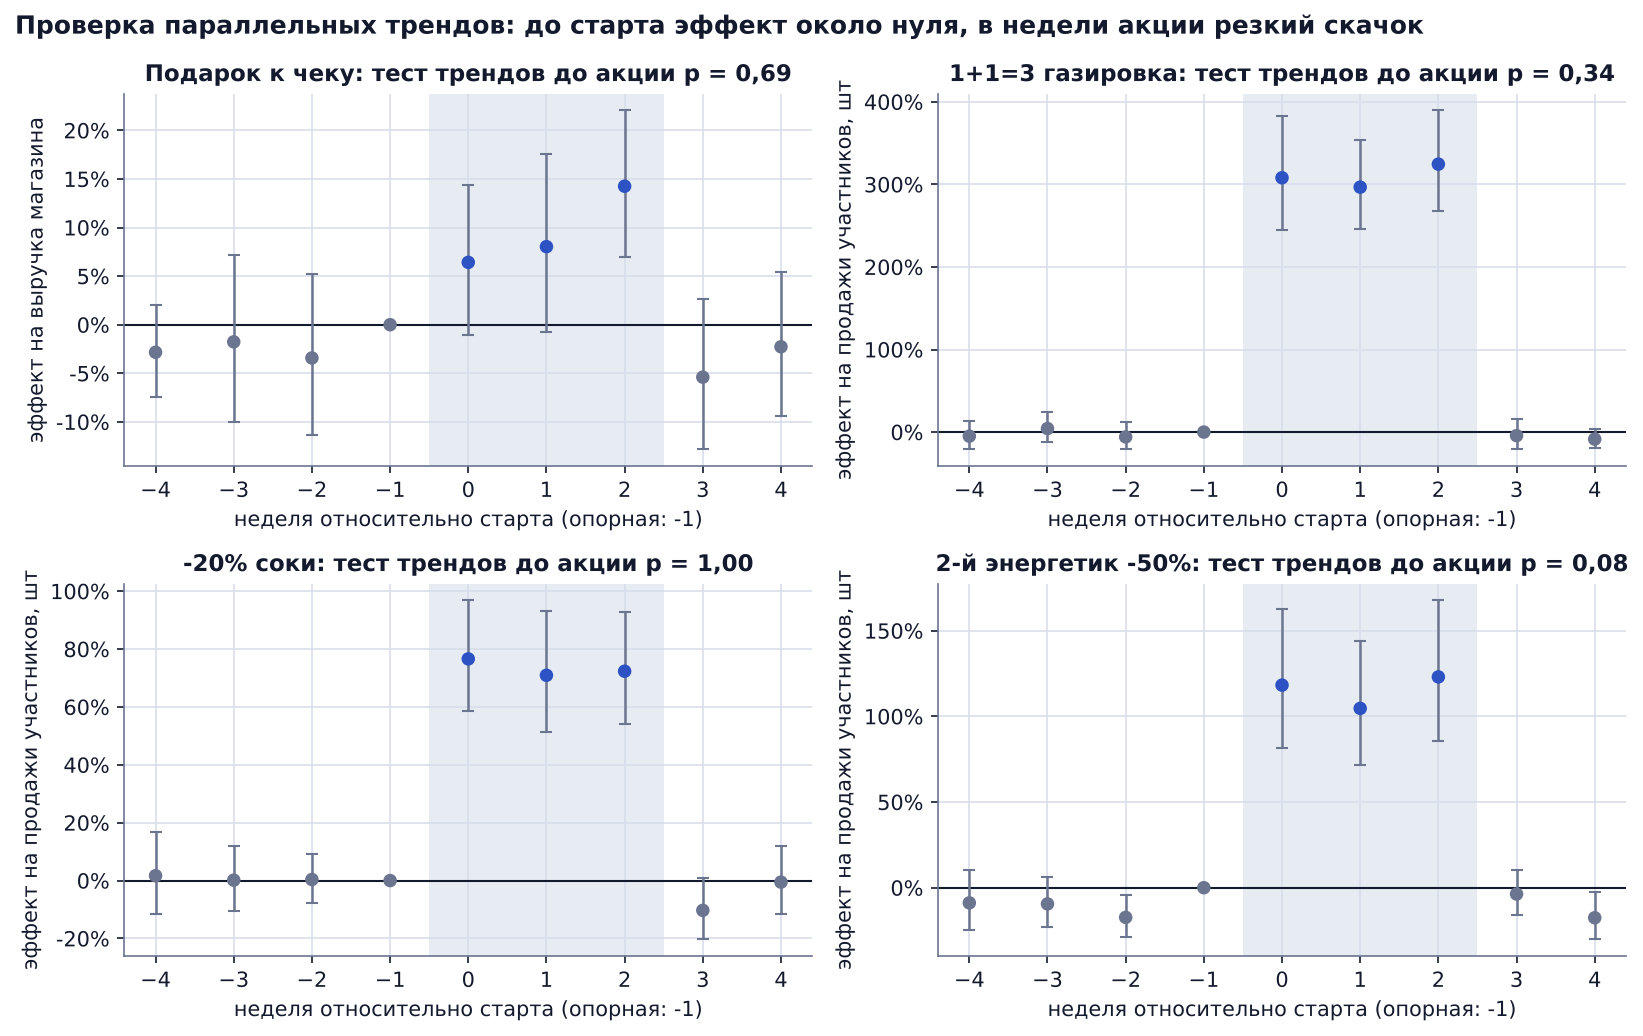

In [10]:
display(Image(filename=str(config.FIGURES / "01_trends_treated_vs_control.png")))
display(Image(filename=str(config.FIGURES / "02_event_study.png")))

У всех акций совместный тест не отвергает параллельность трендов на уровне 5%. У «второго энергетика» p-value ближе к границе (около 0,08): по этой акции вывод стоит перепроверить на следующей волне. После окончания акций показатели возвращаются к контрольной группе.

## 6. Инкрементальный P&L

Правило расчёта:
- товарные акции: эффект на маржу **всей категории** (в нём уже учтены скидки, рост участников и каннибализация соседних товаров), плюс эффект на прочие категории, если он статистически значим;
- акция «подарок к чеку»: эффект на маржу магазина, где себестоимость подарков уже вычтена;
- минус фиксированные затраты волны (материалы, размещение): 30 000 руб.

Статус: «прибыльная» или «убыточная», если эффект на маржу значим на уровне 5%, иначе «эффект не доказан».

In [11]:
pnl = analysis.pnl_table(marts, effects)
pnl[["name", "incr_margin", "incr_margin_ci_low", "incr_margin_ci_high", "p_value",
     "incremental_pnl", "discount_and_gifts", "pnl_per_100_rub_given", "status"]].style.format({
    "incr_margin": "{:,.0f}", "incr_margin_ci_low": "{:,.0f}", "incr_margin_ci_high": "{:,.0f}",
    "p_value": "{:.3f}", "incremental_pnl": "{:,.0f}", "discount_and_gifts": "{:,.0f}",
    "pnl_per_100_rub_given": "{:.1f}"})

,name,incr_margin,incr_margin_ci_low,incr_margin_ci_high,p_value,incremental_pnl,discount_and_gifts,pnl_per_100_rub_given,status
0,Подарок к чеку от 800 руб,"183,850","52,819","314,881",0.006,"153,850","120,150",128.0,прибыльная
1,1+1=3 на газированные напитки,"-90,501","-119,081","-61,922",0.000,"-120,501","464,978",-25.9,убыточная
2,-20% на соки и нектары,"31,171","-12,114","74,456",0.158,"1,171","442,070",0.3,эффект не доказан
3,Второй энергетик за полцены,"-42,362","-60,305","-24,420",0.000,"-72,362","156,835",-46.1,убыточная


Итого по первой волне: -37 842 руб
Потери на убыточных акциях: -192 863 руб
Роздано скидками и подарками: 1 184 033 руб


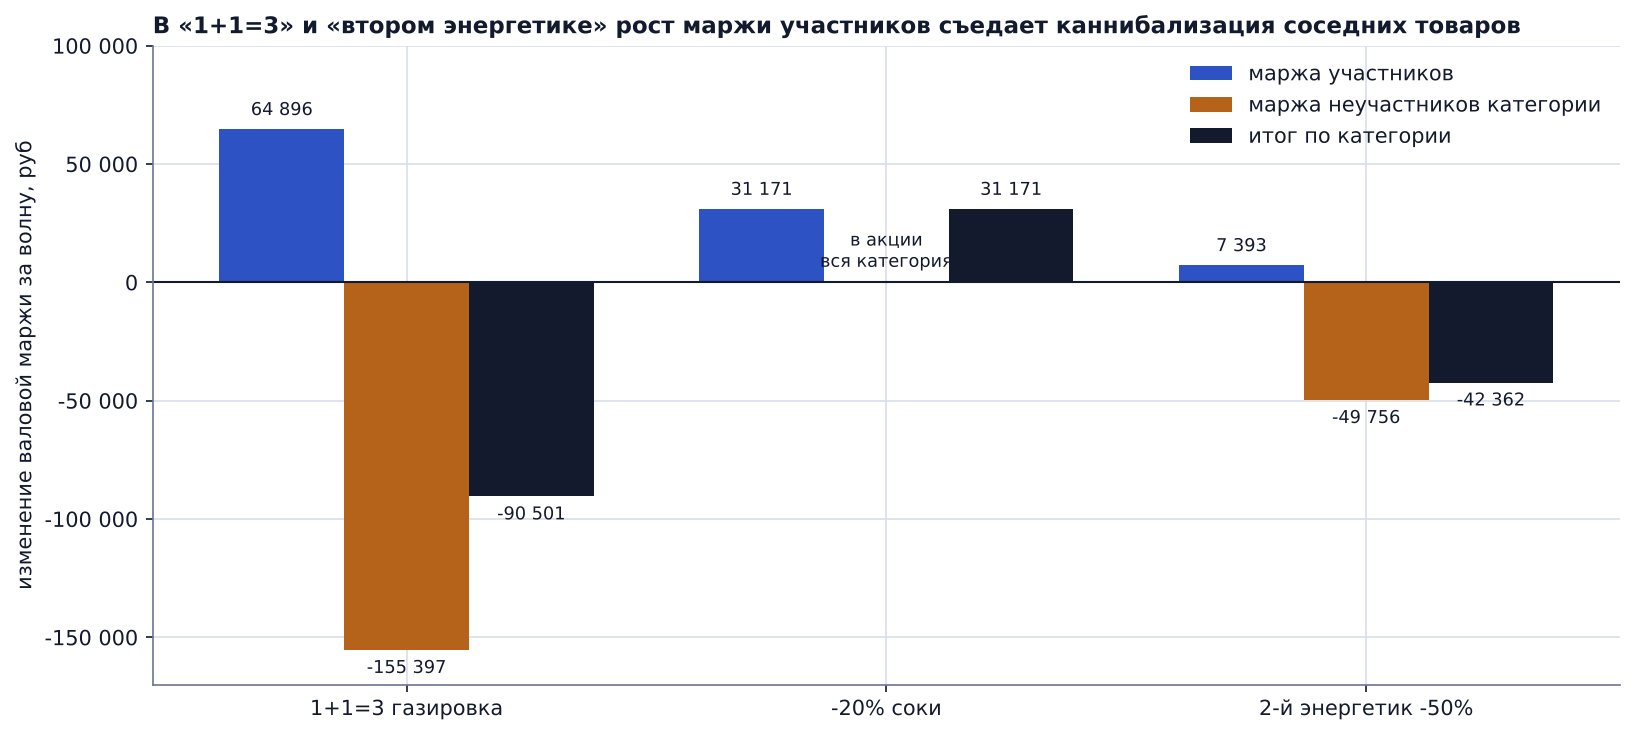

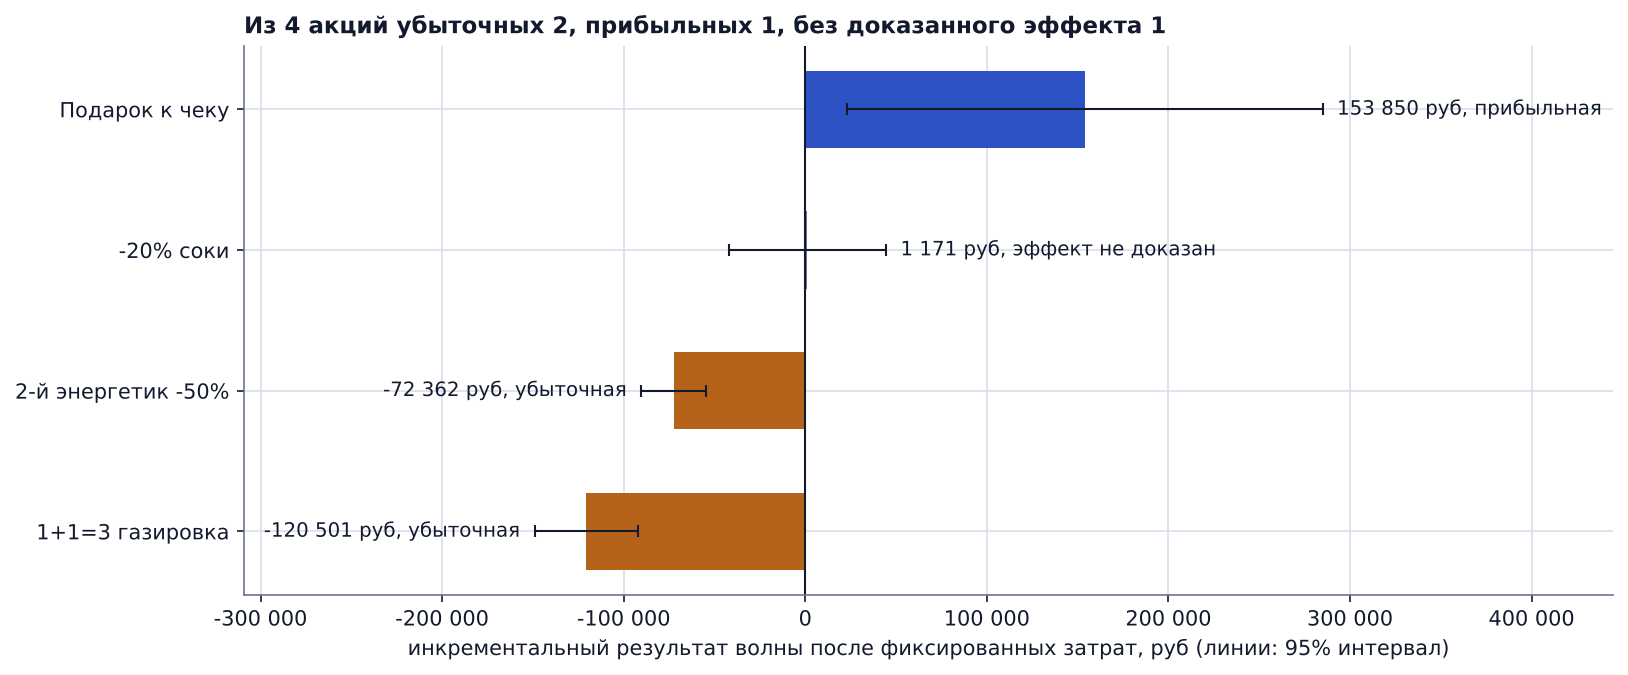

In [12]:
print(f"Итого по первой волне: {pnl.incremental_pnl.round().sum():,.0f} руб".replace(",", " "))
print(f"Потери на убыточных акциях: {pnl.loc[pnl.status == 'убыточная', 'incremental_pnl'].round().sum():,.0f} руб".replace(",", " "))
print(f"Роздано скидками и подарками: {pnl.discount_and_gifts.sum():,.0f} руб".replace(",", " "))
display(Image(filename=str(config.FIGURES / "03_margin_decomposition.png")))
display(Image(filename=str(config.FIGURES / "04_incremental_pnl.png")))

## 7. Точность планирования второй волны

Во второй волне акции P1, P2 и P4 повторили в других магазинах. План продаж участников строится так:

план = база без акции x (1 + эффект акции из первой волны)

База одинакова для обоих подходов: продажи магазинов волны за 3 недели до старта, скорректированные на динамику контрольных магазинов. Подходы различаются только оценкой эффекта: наивная «до/после» или DiD.

In [13]:
plan = analysis.planning_accuracy(marts)
w_naive = analysis.wape(plan.plan_naive, plan.actual_units)
w_did = analysis.wape(plan.plan_did, plan.actual_units)
print(f"WAPE: до/после {w_naive:.1%}, DiD {w_did:.1%}")
plan.style.format({"uplift_naive": "{:.1%}", "uplift_did": "{:.1%}", "baseline_units": "{:,.0f}",
                   "plan_naive": "{:,.0f}", "plan_did": "{:,.0f}", "actual_units": "{:,.0f}",
                   "ape_naive": "{:.1%}", "ape_did": "{:.1%}", "bias_naive": "{:+.1%}", "bias_did": "{:+.1%}"})

WAPE: до/после 6.8%, DiD 2.9%


,promo_id,uplift_naive,uplift_did,baseline_units,plan_naive,plan_did,actual_units,ape_naive,ape_did,bias_naive,bias_did
0,P1-2,347.0%,316.8%,"5,019","22,434","20,918","20,395",10.0%,2.6%,+10.0%,+2.6%
1,P2-2,76.4%,72.3%,"8,627","15,220","14,868","15,404",1.2%,3.5%,-1.2%,-3.5%
2,P4-2,152.7%,136.7%,"3,322","8,394","7,864","7,642",9.8%,2.9%,+9.8%,+2.9%


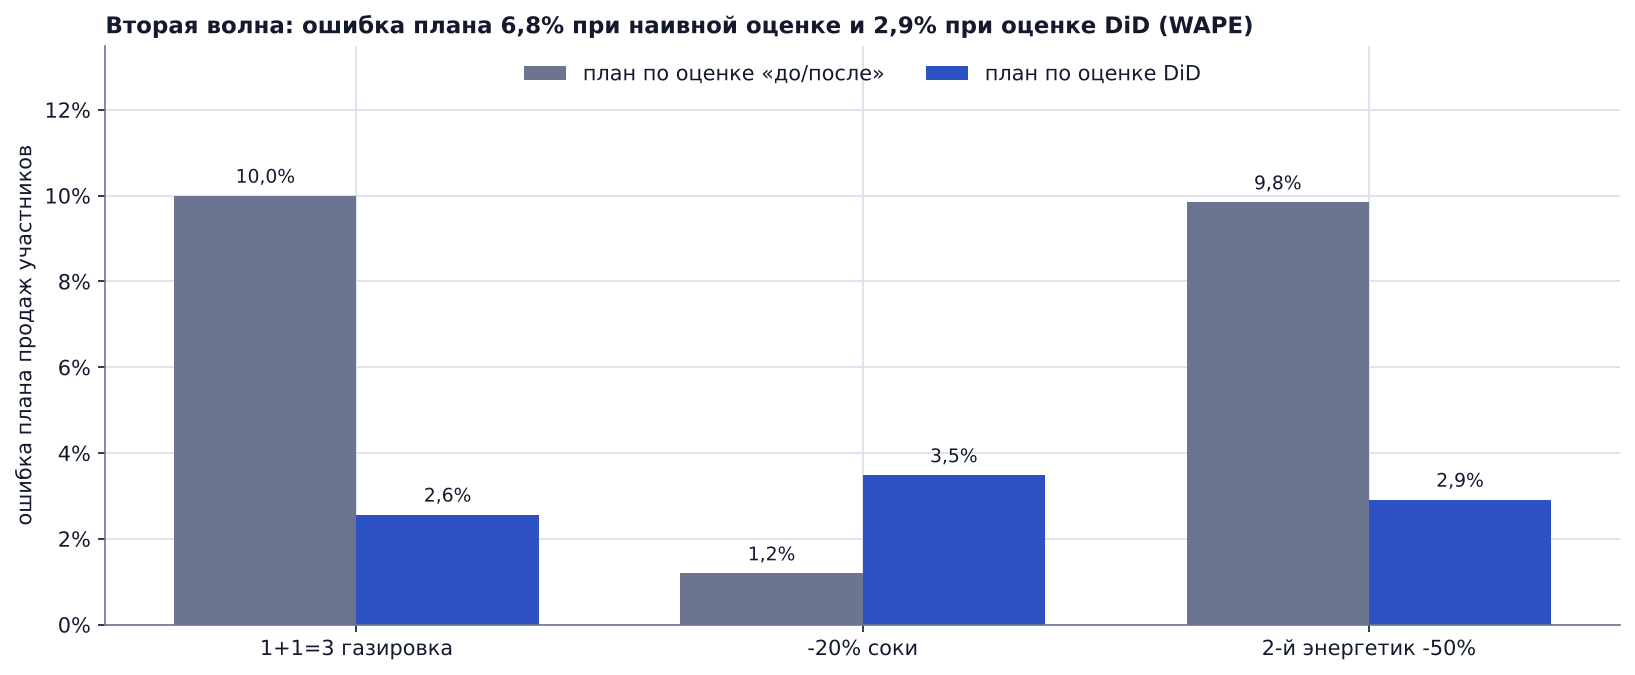

In [14]:
display(Image(filename=str(config.FIGURES / "05_planning_error.png")))

## 8. Выводы и рекомендации

1. **«1+1=3 на газированные напитки»: убыточная.** Продажи участников выросли примерно в 4 раза, но покупатели в основном переключились с соседних товаров категории, а каждая третья бутылка ушла бесплатно. Маржа категории упала. Рекомендация: отказаться от механики или ограничить её товарами без близких заменителей.
2. **«Второй энергетик за полцены»: убыточная.** Та же картина: рост участников за счёт соседних SKU и скидка, которая достаётся тем, кто и так брал два. Рекомендация: снять или заменить на скидку на новинку.
3. **«-20% на соки и нектары»: эффект не доказан.** Продажи выросли, но рост маржи не отличается от нуля статистически, и после фиксированных затрат результат около нуля. Рекомендация: протестировать скидку 10-15%.
4. **«Подарок к чеку от 800 руб»: прибыльная.** Растут и число чеков, и средний чек: покупатели докладывают товары, чтобы получить подарок. Рекомендация: перенести в эту механику бюджет убыточных акций.
5. **Планирование.** Оценка «до/после» приписывает акции сезонный рост и завышает план. Оценка DiD даёт меньшую ошибку плана второй волны (WAPE в таблице выше).

Все цифры получены на синтетических данных и воспроизводятся командой `python -m src.run_pipeline`.